In [32]:
import numpy as np
import matplotlib.pyplot as plt
from localreg import *
from scipy.spatial import distance
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

import sys

sys.path.append("../")
from bblr.lowess import *

In [36]:
np.random.seed(1234)
x = np.linspace(1.5, 5, 500)
yf = np.sin(x*x)
y = yf + 0.5*np.random.randn(*x.shape)

poly = PolynomialFeatures(degree=2, include_bias=False)
poly_features = poly.fit_transform(x.reshape(-1, 1))

poly_reg_model = LinearRegression()
poly_reg_model.fit(poly_features, y)

y_predicted = poly_reg_model.predict(poly_features)

param = 0.3
ci = True

lowess = LOWESSRegressor(frac=param)
lowess.fit(poly_features, y)
y_pred, coefs, intercepts, cis_raw, std_errors = lowess.predict(poly_features, return_ci=ci)

y_prim_true = 2*x*np.cos(x*x)
est_derivative = coefs[:,0] + coefs[:,1]*2*x

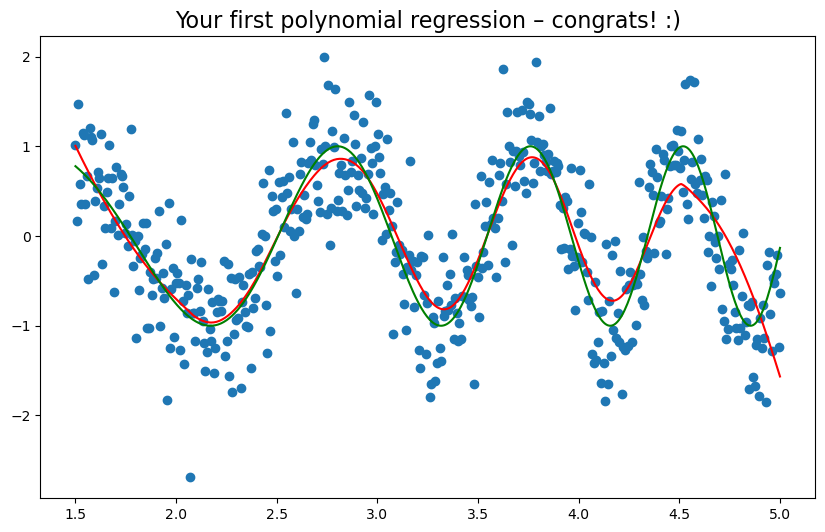

In [37]:
plt.figure(figsize=(10, 6))
plt.title("Your first polynomial regression – congrats! :)", size=16)
plt.scatter(x, y)
plt.plot(x, y_pred, c="red")
plt.plot(x, yf, c="green")
plt.show()

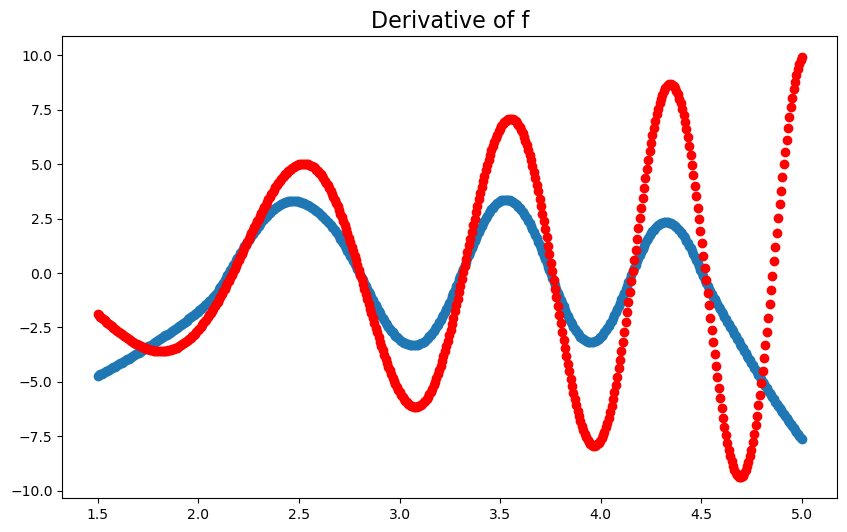

In [41]:
y_prim_true = 2*x*np.cos(x*x)
est_derivative = coefs[:,0] + coefs[:,1]*2*x

plt.figure(figsize=(10, 6))
plt.title("Derivative of f", size=16)
plt.scatter(x, est_derivative, label = "est")
plt.scatter(x, y_prim_true, label = "true", c="red")
# plt.plot(x, y_pred, c="red")
plt.show()

In [44]:
np.random.seed(1234)
x = np.linspace(1.5, 5, 500)
yf = np.sin(x*x)
y = yf + 0.5*np.random.randn(*x.shape)

poly = PolynomialFeatures(degree=3, include_bias=False)
poly_features = poly.fit_transform(x.reshape(-1, 1))

poly_reg_model = LinearRegression()
poly_reg_model.fit(poly_features, y)

y_predicted = poly_reg_model.predict(poly_features)

param = 0.3
ci = True

lowess = LOWESSRegressor(frac=param)
lowess.fit(poly_features, y)
y_pred, coefs, intercepts, cis_raw, std_errors = lowess.predict(poly_features, return_ci=ci)

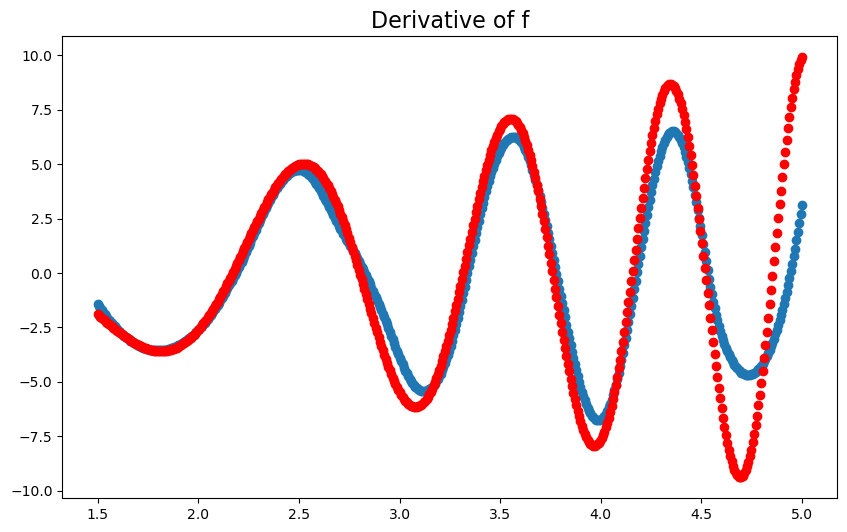

In [45]:
y_prim_true = 2*x*np.cos(x*x)
est_derivative = coefs[:,0] + coefs[:,1]*2*x + coefs[:,2]*3*x**2

plt.figure(figsize=(10, 6))
plt.title("Derivative of f", size=16)
plt.scatter(x, est_derivative, label = "est")
plt.scatter(x, y_prim_true, label = "true", c="red")
# plt.plot(x, y_pred, c="red")
plt.show()

In [ ]:
class LocalPolynomialRegression:
    """
    Local polynomial regression with derivative estimation.
    
    Parameters:
    -----------
    degree : int
        Degree of polynomial (2 or 3)
    frac : float or array-like
        Fraction parameter for LOWESS
    """

    def __init__(self, degree=2, frac=0.3, ci=False):
        if degree not in [2, 3]:
            raise ValueError("Only degree 2 and 3 are supported")
        self.degree = degree
        self.frac = frac
        self.X_train = None
        self.y_train = None
        self.ci = ci

    def fit(self, X, y):
        """Store training data"""
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        self.d = self.X_train.ndim
        if self.d == 1:
            self.X_train = self.X_train.reshape(-1, 1)
        return self

    def predict(self, X_test, return_derivatives=True):
        """
        Predict at new points with optional derivative estimation.
        
        Parameters:
        -----------
        X_test : array-like, shape (n_pred, d)
            Points at which to predict
        return_derivatives : bool
            If True, also return derivative estimates
            
        Returns:
        --------
        y_pred : array, shape (n_pred,)
            Predicted values
        derivatives : array, shape (n_pred, d), optional
            Predicted derivatives for each dimension
        """

        poly = PolynomialFeatures(degree=self.degree, include_bias=False)
        poly_features = poly.fit_transform(x.reshape(-1, 1))

        poly_reg_lowess = LOWESSRegressor(frac=param)
        poly_reg_lowess.fit(poly_features, y)
        y_pred, raw_coefs, intercepts, cis_raw, std_errors = lowess.predict(poly_features, return_ci=ci)

        match self.degree:
            case 2:
                coefs = [np.array(raw_coefs[:, j + 0] + raw_coefs[:, j + 1]*2*x) for j in range(self.d)]
            case 3:
                coefs = [np.array(raw_coefs[:, j + 0] + raw_coefs[:, j + 1]*2*x + raw_coefs[:, j + 2]*3*x**2) for j in range(self.d)]

        # TODO: do the confidence intervals and standard errors computations if necessary, but I don't think it is necessary

        return y_pred, coefs, intercepts, cis_raw, std_errors

In [47]:
lpr = LocalPolynomialRegression(degree=3, frac=0.3, ci=False)
lpr.fit(x, y)
y_pred, coefs, intercepts, cis_raw, std_errors = lpr.predict(x)

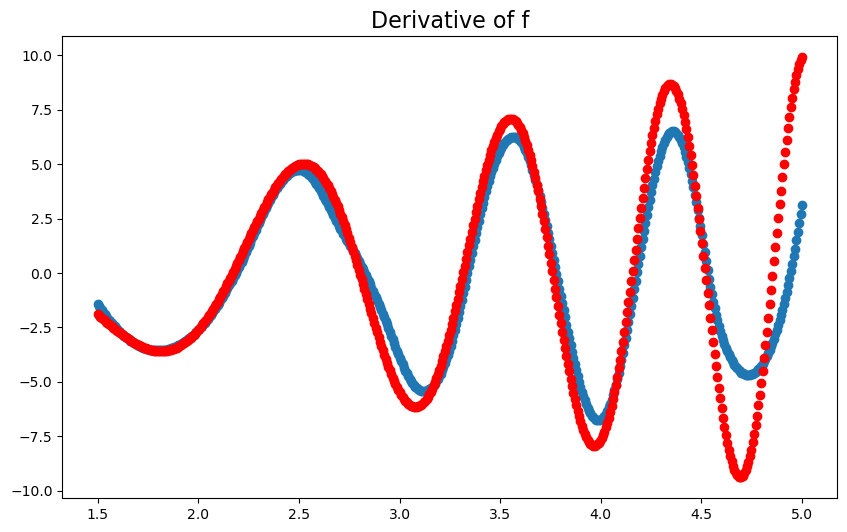

In [50]:
y_prim_true = 2*x*np.cos(x*x)

plt.figure(figsize=(10, 6))
plt.title("Derivative of f", size=16)
plt.scatter(x, coefs[0], label = "est")
plt.scatter(x, y_prim_true, label = "true", c="red")
# plt.plot(x, y_pred, c="red")
plt.show()

In [52]:
np.set_printoptions(suppress=True)

intercepts

array([  -40.05279826,   -40.03960352,   -40.02632569,   -40.01296525,
         -39.99952998,   -39.98602759,   -39.97246249,   -39.95884404,
         -39.94518703,   -39.93150553,   -39.91781206,   -39.90411319,
         -39.89041743,   -39.87673694,   -39.86308627,   -39.8494794 ,
         -39.83593066,   -39.82245518,   -39.80906869,   -39.79578679,
         -39.78262432,   -39.76960101,   -39.75674064,   -39.74407155,
         -39.73162347,   -39.71942347,   -39.70749297,   -39.69585492,
         -39.68453348,   -39.67356812,   -39.66300458,   -39.65288427,
         -39.64325261,   -39.63415357,   -39.62561955,   -39.61766793,
         -39.61030369,   -39.60352957,   -39.5973471 ,   -39.59175774,
         -39.58674288,   -39.58224292,   -39.57818219,   -39.5744832 ,
         -39.57106794,   -39.56787998,   -39.56486372,   -39.56197067,
         -39.55915237,   -39.55635176,   -39.5534914 ,   -39.55047408,
         -39.54718121,   -39.54350492,   -39.53935374,   -39.53463547,
      